In [1]:
import os
import sys
from pathlib import Path
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
from matplotlib.patches import Patch

# -------------------------------------------------------------------
# Read Impacts Geodatabase 
# -------------------------------------------------------------------

impacts = gpd.read_file(
    '../out/san_mateo_impacts.gpkg',
    layer='impacts_wgs84'
)

ar_df = pd.read_csv('../out/san_mateo_ar_database.csv')


ar_impact_df = pd.read_csv("../out/san_mateo_ar-impact_database.csv")

# -------------------------------------------------------------------
# Make sure datetime columns are datetime64
# -------------------------------------------------------------------

ar_df['ar_start'] = pd.to_datetime(ar_df['ar_start'], utc=True)
ar_df['ar_end']   = pd.to_datetime(ar_df['ar_end'], utc=True)

ar_df['smc_start'] = pd.to_datetime(ar_df['smc_start'], utc=True)
ar_df['smc_end']   = pd.to_datetime(ar_df['smc_end'], utc=True)

impacts['date'] = pd.to_datetime(
    impacts['date'],
    utc=True,
    format='mixed'
)

impact_colors = {
    'Debris Flow': '#B5A18A',
    'Flash Flood': '#4F81A8',
    'Flood': '#76B7D4',
    'Hail': '#8A8A8A',
    'Heavy Rain': '#234A78',
    'Landslide': '#8C5A3C'
}


In [2]:
# --- Check to see if we are double counting impacts --- 
multiple_ar = (
    ar_impact_df
    .groupby('impact_id')['ARID']
    .nunique()
)

print(
    multiple_ar[multiple_ar > 1]
)

impact_id
CGS_000     4
CGS_004     2
CGS_005     2
CGS_006     2
CGS_007     2
CGS_008     2
CGS_009     2
CGS_012     2
CGS_014     2
CGS_017     2
NOAA_026    2
NOAA_028    2
NOAA_032    2
NOAA_033    2
NOAA_034    2
NOAA_037    3
NOAA_038    3
NOAA_039    3
NOAA_040    3
NOAA_041    2
NOAA_046    2
NOAA_049    3
NOAA_052    3
NOAA_053    3
NOAA_055    2
NOAA_056    2
NOAA_057    2
NOAA_058    2
NOAA_059    2
NOAA_060    2
NOAA_062    2
NOAA_063    2
NOAA_064    2
NOAA_065    2
NOAA_066    2
NOAA_067    2
NOAA_068    2
NOAA_075    2
NOAA_076    2
NOAA_077    2
NOAA_078    2
NOAA_079    3
NOAA_081    2
NOAA_082    2
NOAA_084    3
NOAA_091    3
NOAA_100    2
NOAA_101    2
NOAA_106    3
NOAA_107    2
NOAA_109    2
NOAA_110    2
Name: ARID, dtype: int64


In [3]:
# ------------------------------------------------------------
# Assign one AR relationship to each unique impact
# ------------------------------------------------------------

relationship_priority = {
    'during_AR': 3,
    'post_AR': 2,
    'pre_AR': 1
}

ar_relationships = ar_impact_df.copy()

ar_relationships['priority'] = (
    ar_relationships['relationship']
    .map(relationship_priority)
)

# Highest-priority relationship for each impact
impact_relationship = (
    ar_relationships
    .sort_values(
        ['impact_id', 'priority'],
        ascending=[True, False]
    )
    .drop_duplicates('impact_id')
    [['impact_id', 'relationship']]
)

print(impact_relationship['relationship'].value_counts())

relationship
during_AR    60
post_AR      21
pre_AR        7
Name: count, dtype: int64


In [4]:
print(
    f"Unique impacts with AR relationships: "
    f"{impact_relationship['impact_id'].nunique()}"
)

Unique impacts with AR relationships: 88


In [5]:
# ------------------------------------------------------------
# Prepare impact data
# ------------------------------------------------------------

impact_plot = impacts[
    ['impact_id', 'date', 'impact_type']
].copy()

impact_plot['date'] = pd.to_datetime(
    impact_plot['date'],
    utc=True
)

impact_plot['year'] = impact_plot['date'].dt.year


# ------------------------------------------------------------
# Add AR relationship
# ------------------------------------------------------------
impact_plot = impact_plot.merge(
    impact_relationship,
    on='impact_id',
    how='left'
)

# impact_plot = impact_plot.merge(
#     ar_impact_df[
#         ['impact_id', 'relationship']
#     ],
#     on='impact_id',
#     how='left'
# )

# Impacts with no AR relationship
impact_plot['relationship'] = (
    impact_plot['relationship']
    .fillna('no_AR')
)

print(
    impact_plot[
        ['impact_id', 'date', 'impact_type', 'relationship']
    ].head()
)

  impact_id                      date impact_type relationship
0   CGS_000 2019-12-02 16:00:00+00:00   Landslide      post_AR
1   CGS_001 2023-01-01 08:33:38+00:00   Landslide      post_AR
2   CGS_002 2023-01-01 12:35:15+00:00   Landslide      post_AR
3   CGS_003 2023-01-01 12:37:28+00:00   Landslide      post_AR
4   CGS_004 2023-01-10 08:02:50+00:00   Landslide    during_AR


In [6]:
# --- Check that these two numbers are identical ---
# --- One row per impact ---
print(len(impact_plot))
print(impact_plot['impact_id'].nunique())

100
100


In [11]:
impact_plot

,impact_id,date,impact_type,year,relationship
0,CGS_000,2019-12-02 16:00:00+00:00,Landslide,2019,post_AR
1,CGS_001,2023-01-01 08:33:38+00:00,Landslide,2023,post_AR
2,CGS_002,2023-01-01 12:35:15+00:00,Landslide,2023,post_AR
3,CGS_003,2023-01-01 12:37:28+00:00,Landslide,2023,post_AR
4,CGS_004,2023-01-10 08:02:50+00:00,Landslide,2023,during_AR
...,...,...,...,...,...
95,NOAA_106,2024-03-01 00:00:00+00:00,Flood,2024,during_AR
96,NOAA_107,2024-03-30 00:00:00+00:00,Hail,2024,during_AR
97,NOAA_108,2024-02-04 00:00:00+00:00,Flood,2024,pre_AR
98,NOAA_109,2024-12-14 00:00:00+00:00,Flood,2024,during_AR


In [7]:
print(
    impact_plot['relationship']
    .value_counts(dropna=False)
)

relationship
during_AR    60
post_AR      21
no_AR        12
pre_AR        7
Name: count, dtype: int64


In [8]:
# ------------------------------------------------------------
# Annual counts
# ------------------------------------------------------------

annual_counts = (
    impact_plot[
        impact_plot['relationship'].isin(
            ['during_AR', 'post_AR']
        )
    ]
    .groupby(
        ['year', 'impact_type', 'relationship']
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Make sure both columns exist
for col in ['during_AR', 'post_AR']:
    if col not in annual_counts.columns:
        annual_counts[col] = 0

annual_counts

relationship,year,impact_type,during_AR,post_AR
0,2005,Flood,1,0
1,2006,Flood,0,1
2,2009,Flood,1,0
3,2009,Heavy Rain,2,0
4,2010,Flood,0,3
5,2012,Flash Flood,0,4
6,2012,Heavy Rain,1,0
7,2014,Flash Flood,3,0
8,2014,Flood,1,2
9,2015,Flood,2,0


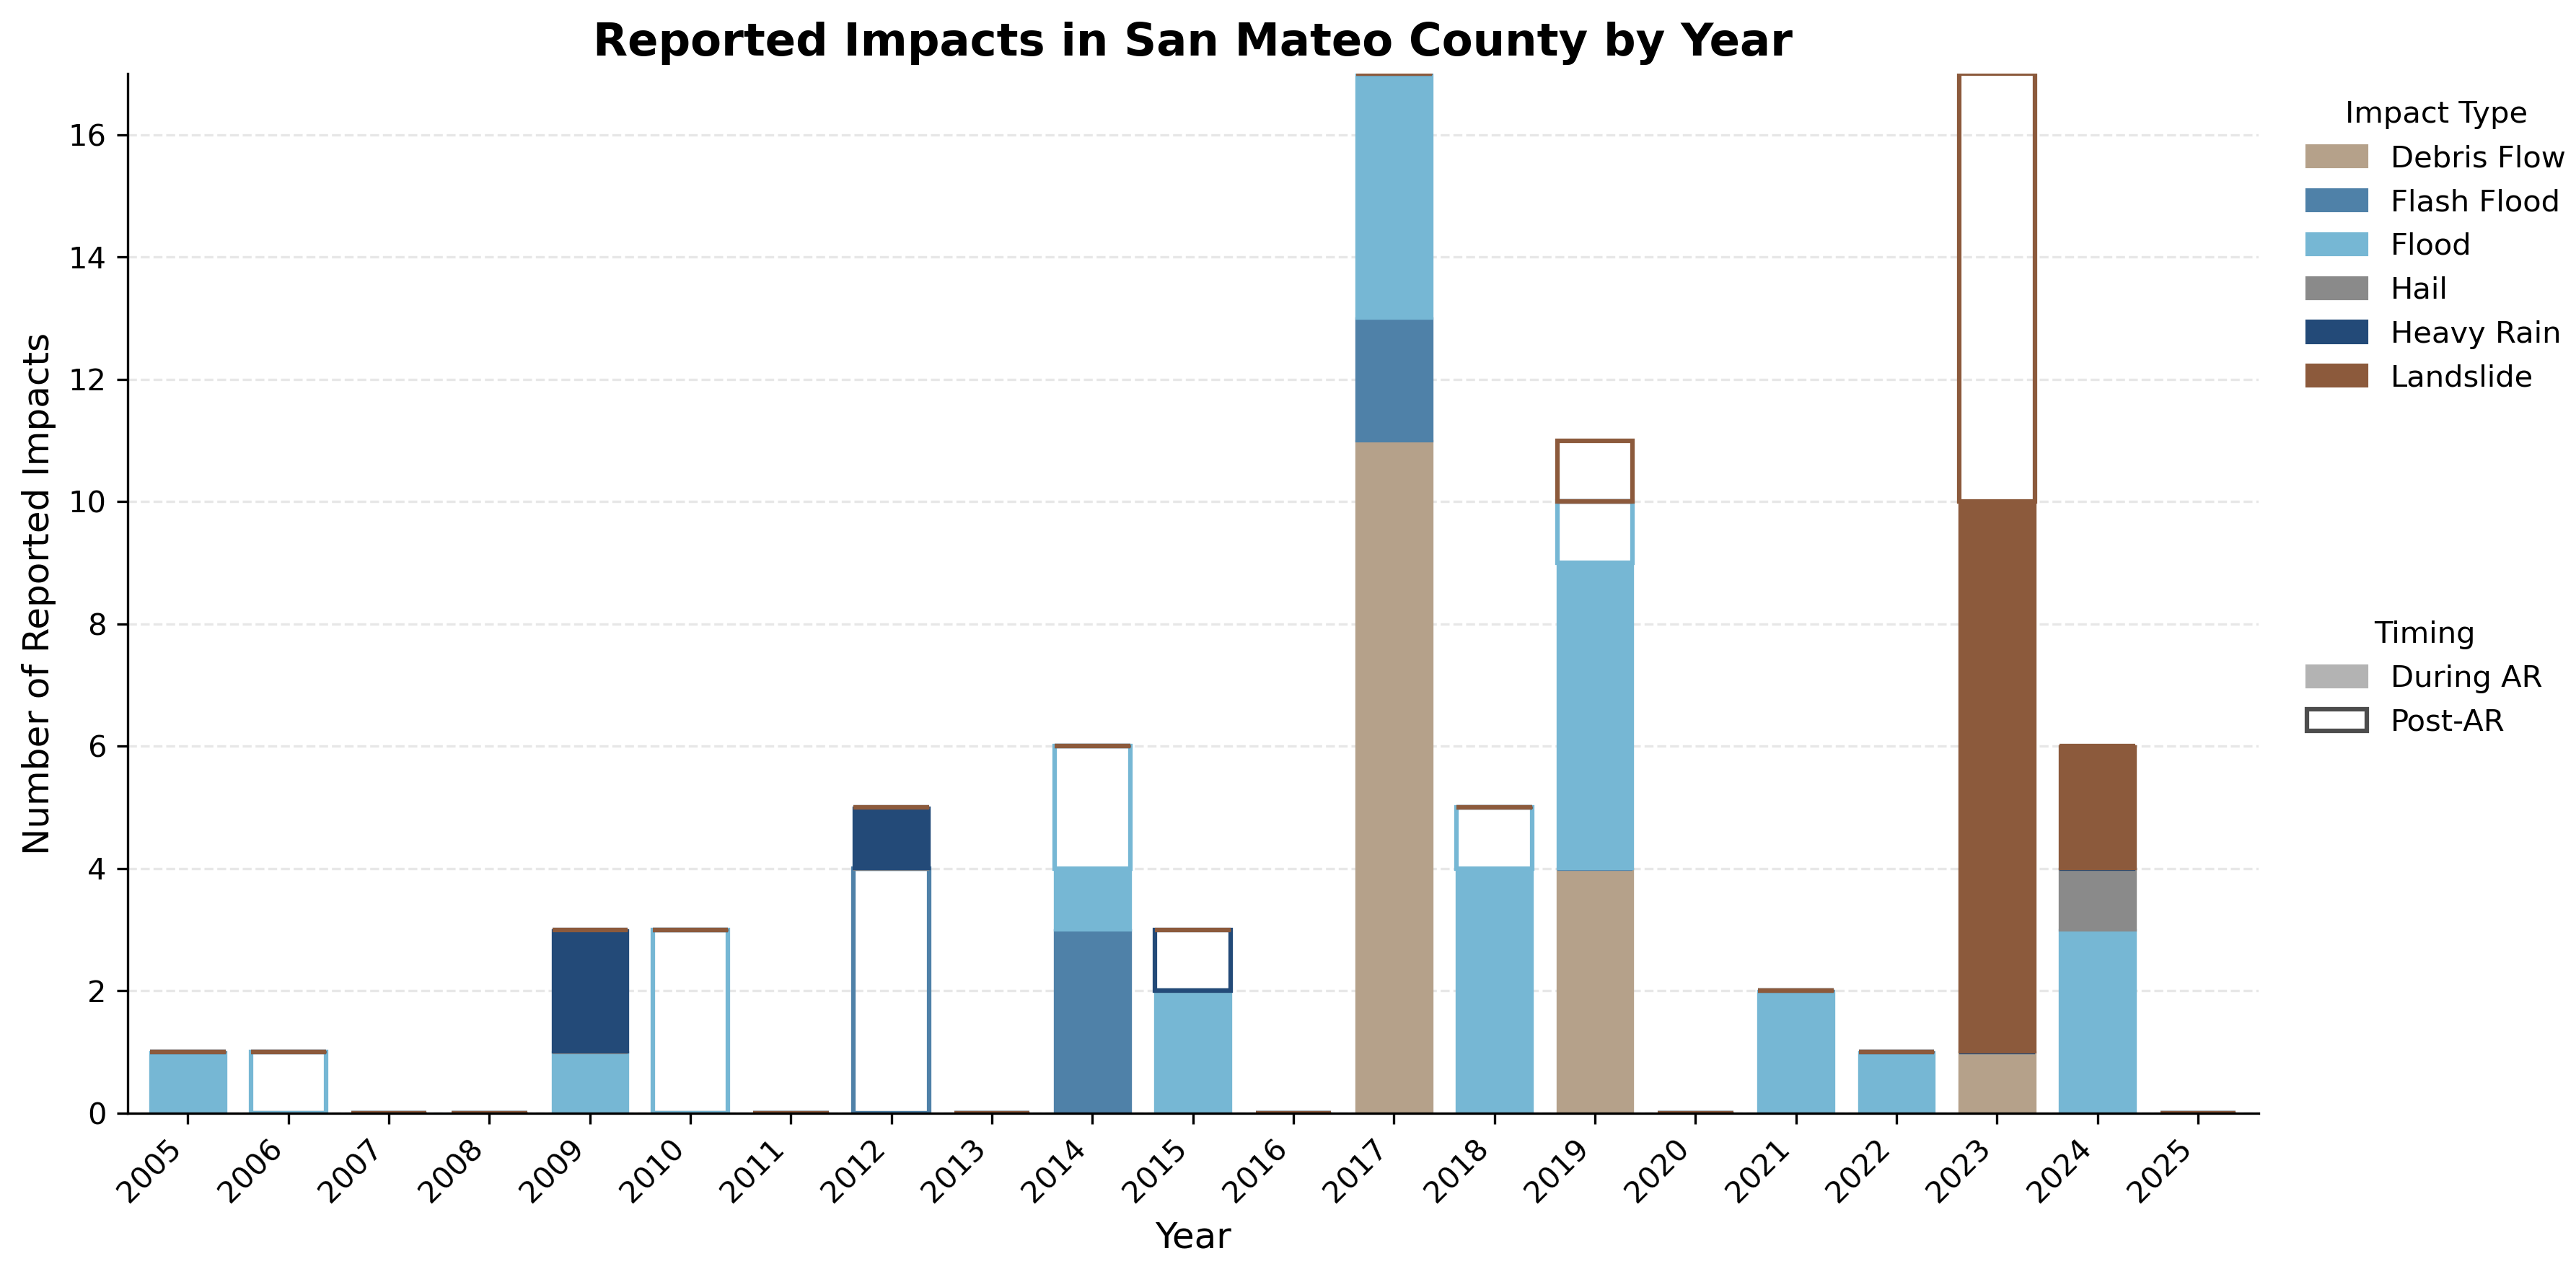

In [9]:
# ------------------------------------------------------------
# Plot annual impact counts
# ------------------------------------------------------------

years = np.arange(
    impact_plot['year'].min(),
    impact_plot['year'].max() + 1
)

impact_types = [
    impact_type
    for impact_type in impact_colors
    if impact_type in impact_plot['impact_type'].unique()
]

fig, ax = plt.subplots(
    figsize=(12, 6),
    dpi=300
)

# Track where each segment should start
bottom = np.zeros(len(years))

for impact_type in impact_types:

    # Get counts for this impact type
    type_data = (
        annual_counts[
            annual_counts['impact_type'] == impact_type
        ]
        .set_index('year')
        .reindex(years, fill_value=0)
    )

    during = type_data['during_AR'].values
    post = type_data['post_AR'].values

    color = impact_colors[impact_type]

    # --------------------------------------------------------
    # During AR = filled
    # --------------------------------------------------------

    ax.bar(
        years,
        during,
        bottom=bottom,
        width=0.75,
        color=color,
        edgecolor=color,
        linewidth=0.8,
        label=impact_type
    )

    bottom += during

    # --------------------------------------------------------
    # Post AR = outlined
    # --------------------------------------------------------

    ax.bar(
        years,
        post,
        bottom=bottom,
        width=0.75,
        facecolor='none',
        edgecolor=color,
        linewidth=1.5
    )

    bottom += post


# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_xlabel(
    'Year',
    fontsize=12
)

ax.set_ylabel(
    'Number of Reported Impacts',
    fontsize=12
)

ax.set_title(
    'Reported Impacts in San Mateo County by Year',
    fontsize=15,
    fontweight='bold'
)

ax.set_xticks(years)
ax.set_xticklabels(
    years,
    rotation=45,
    ha='right'
)

ax.set_xlim(
    years.min() - 0.6,
    years.max() + 0.6
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.3,
    zorder=0
)

ax.set_axisbelow(True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

# Impact type legend
impact_handles = [
    Patch(
        facecolor=impact_colors[impact_type],
        edgecolor=impact_colors[impact_type],
        label=impact_type
    )
    for impact_type in impact_types
]

# AR relationship legend
relationship_handles = [
    Patch(
        facecolor='0.7',
        edgecolor='0.7',
        label='During AR'
    ),
    Patch(
        facecolor='none',
        edgecolor='0.3',
        linewidth=1.5,
        label='Post-AR'
    )
]

legend1 = ax.legend(
    handles=impact_handles,
    title='Impact Type',
    loc='upper left',
    bbox_to_anchor=(1.01, 1.0),
    frameon=False
)

ax.add_artist(legend1)

ax.legend(
    handles=relationship_handles,
    title='Timing',
    loc='upper left',
    bbox_to_anchor=(1.01, 0.50),
    frameon=False
)

plt.tight_layout()

plt.show()

In [10]:
# ---------------------------------------------------------------------
# Save Figure
# ---------------------------------------------------------------------

output_path = Path('../figs/AR_impacts_timeline.png')
fig.savefig(output_path, bbox_inches='tight', dpi=fig.dpi)

print(f"Saved figure to: {output_path.resolve()}")

Saved figure to: /cw3e/mead/projects/cwp140/repos/AR_hazard_tool/figs/AR_impacts_timeline.png
